In [1]:
import numpy, pandas, matplotlib, seaborn, sklearn
print("All libraries found")
print("scikit-learn version:", sklearn.__version__)

All libraries found
scikit-learn version: 1.9.0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris(as_frame=True)

# Create the DataFrame
df = iris.data.copy()
df["species"] = iris.target_names[iris.target]

# Display the first five rows
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Summary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


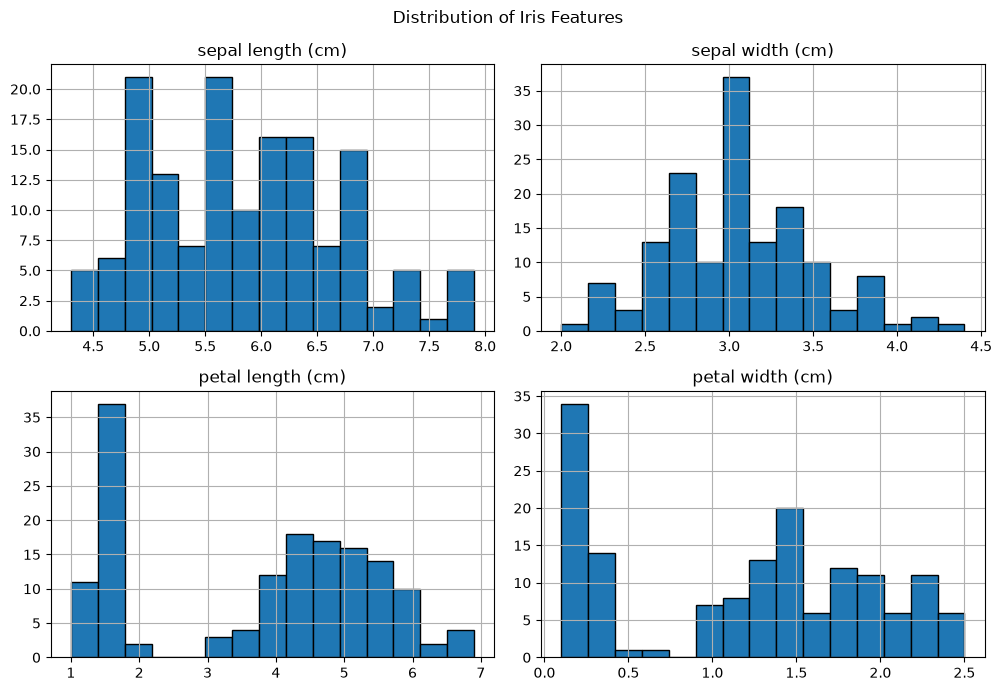

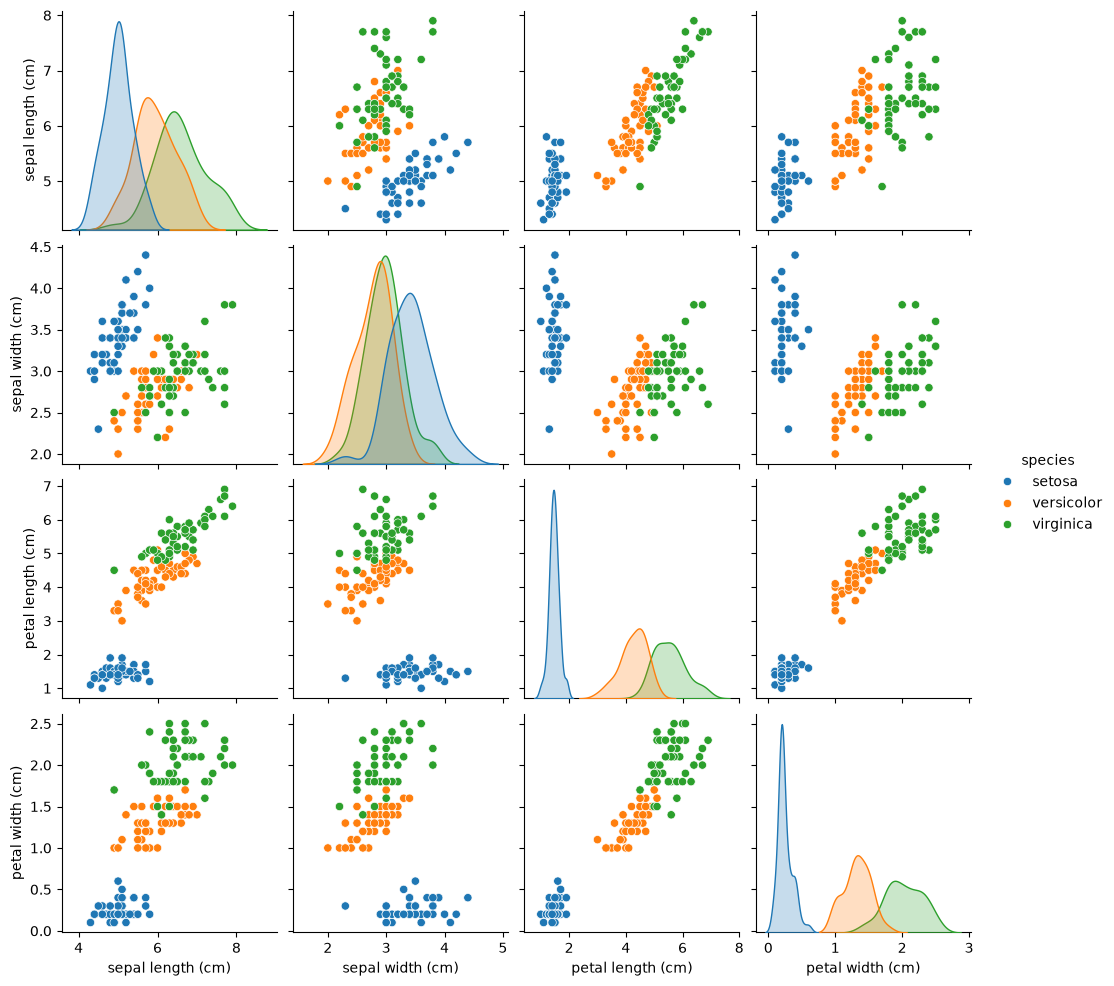

In [4]:
# Distribution of the four numerical features
df.drop(columns="species").hist(
    figsize=(10, 7),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

# Relationships between features
sns.pairplot(df, hue="species")
plt.show()

In [5]:
# Select only numerical features
X = df.drop(columns=["species"])

print("Original feature means:")
display(X.mean())

print("\nOriginal feature standard deviations:")
display(X.std())

Original feature means:


sepal length (cm)    5.843333
sepal width (cm)     3.057333
petal length (cm)    3.758000
petal width (cm)     1.199333
dtype: float64


Original feature standard deviations:


sepal length (cm)    0.828066
sepal width (cm)     0.435866
petal length (cm)    1.765298
petal width (cm)     0.762238
dtype: float64

In [6]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit and transform the features
X_scaled_array = scaler.fit_transform(X)

# Convert the scaled array back into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X.columns,
    index=X.index
)

print("Scaled feature means:")
display(X_scaled.mean().round(3))

print("\nScaled feature standard deviations:")
display(X_scaled.std().round(3))

print("\nFirst five scaled samples:")
display(X_scaled.head())

Scaled feature means:


sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64


Scaled feature standard deviations:


sepal length (cm)    1.003
sepal width (cm)     1.003
petal length (cm)    1.003
petal width (cm)     1.003
dtype: float64


First five scaled samples:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


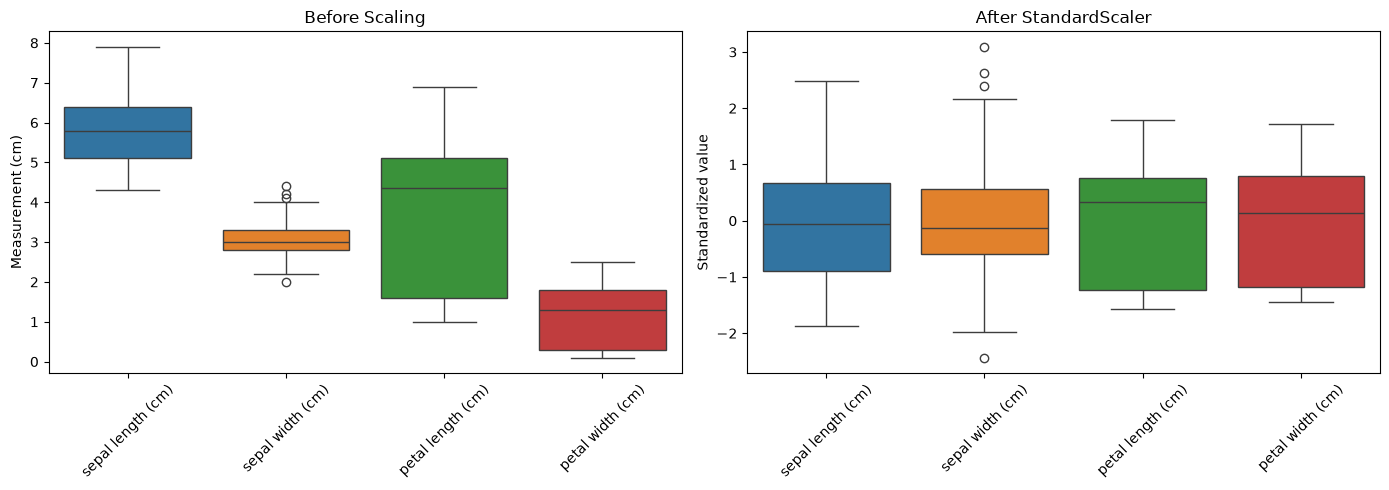

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=X, ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Measurement (cm)")

sns.boxplot(data=X_scaled, ax=axes[1])
axes[1].set_title("After StandardScaler")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylabel("Standardized value")

plt.tight_layout()
plt.show()

### Step 2: Feature Scaling

The four numerical features of the Iris dataset have different means, ranges, and standard deviations. Since K-Means uses Euclidean distance, features with larger numerical variation may disproportionately influence the clustering results.

To address this, StandardScaler was applied to standardize each feature using its mean and standard deviation. The transformed features have approximately zero mean and unit variance.

Scaling is appropriate for K-Means because it helps each feature contribute on a more comparable scale to the distance calculations. The original species labels were excluded from the clustering features.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    # Fit K-Means on the scaled features
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    # Store evaluation metrics
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, cluster_labels)
    )

# Display the results
results = pd.DataFrame({
    "Number of clusters (k)": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(results.round(4))

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,Number of clusters (k),Inertia,Silhouette Score
0,2,222.3617,0.5818
1,3,139.8205,0.4599
2,4,114.0925,0.3869
3,5,90.9275,0.3459
4,6,81.5444,0.3171
5,7,72.6311,0.3202
6,8,62.5406,0.3387
7,9,55.1195,0.3424
8,10,47.3910,0.3518


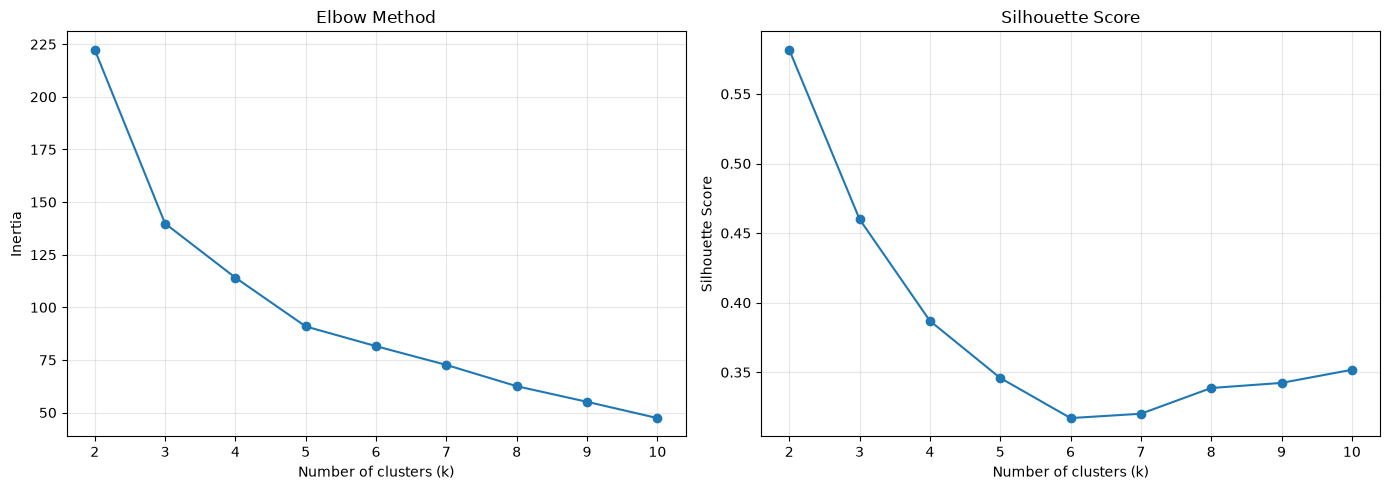

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(
    list(k_values), inertias,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True, alpha=0.3)

# Silhouette plot
axes[1].plot(
    list(k_values), silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Step 3: Choosing the Number of Clusters

The Elbow Method and Silhouette Score were used to investigate the appropriate number of clusters using standardized numerical features.

The silhouette score was highest at k = 2, with a value of 0.5818, indicating better cluster cohesion and separation than the other tested values according to this metric. The elbow curve showed a substantial reduction in inertia between k = 2 and k = 3, followed by more gradual reductions.

Although k = 2 achieved the highest silhouette score, k = 3 was selected as the primary candidate for further analysis because it allows a useful investigation of the dataset's potential grouping structure. This choice is a trade-off rather than a claim that k = 3 is optimal under every metric. The species labels were not used to select the clusters.

In [10]:
# Step 4: Fit the final K-Means model

best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Fit using only the scaled numerical features
cluster_labels = kmeans.fit_predict(X_scaled)

# Store the cluster assignments
df["cluster"] = cluster_labels

print("Cluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nFirst 10 cluster assignments:")
display(df[["cluster"]].head(10))

Cluster sizes:
cluster
0    53
1    50
2    47
Name: count, dtype: int64

First 10 cluster assignments:


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,cluster
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


In [11]:
# Step 5: Reduce the data to two dimensions using PCA

from sklearn.decomposition import PCA

# Create PCA with two components
pca = PCA(n_components=2)

# Transform the scaled features
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=X_scaled.index
)

# Add the existing K-Means cluster assignments
pca_df["cluster"] = cluster_labels

print("PCA output shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_.round(4))

print(
    "\nTotal variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA output shape: (150, 2)

Explained variance ratio:
[0.7296 0.2285]

Total variance explained by two components: 95.81 %


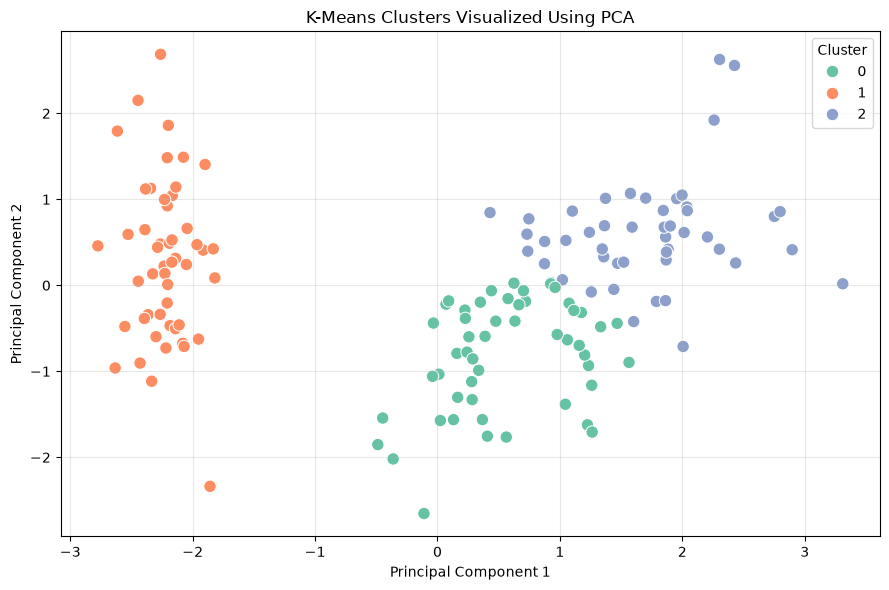

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=80
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 5: PCA-Based Cluster Visualization

Principal Component Analysis (PCA) was applied to the four standardized numerical features to reduce the data to two dimensions for visualization.

The first two principal components were used to create a scatter plot, with points colored according to their K-Means cluster assignments. This visualization helps examine the degree of separation and overlap between clusters.

PCA was used only for visualization. The K-Means model was fitted using all four standardized features, preserving more information than clustering directly on the two-dimensional projection. Since PCA reduces dimensionality, some separation visible in the original four-dimensional feature space may not be fully represented in the plot.

In [13]:
# Step 6: Interpret clusters using feature means

feature_columns = iris.feature_names

cluster_means = df.groupby("cluster")[feature_columns].mean()

print("Mean feature values for each cluster:")
display(cluster_means.round(2))

Mean feature values for each cluster:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


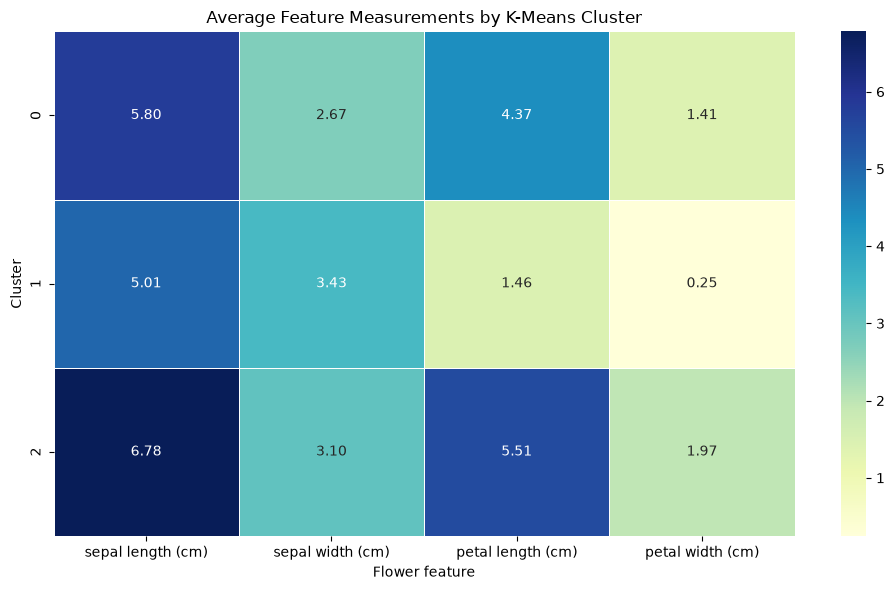

In [14]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Feature Measurements by K-Means Cluster")
plt.xlabel("Flower feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

### Step 6: Cluster Interpretation

The mean values of the four original numerical features were calculated for each K-Means cluster. These averages help describe the characteristics of the groups identified by the algorithm.

Differences in sepal and petal measurements indicate which features contribute to distinguishing the clusters. The cluster IDs are arbitrary labels and do not represent any predefined species.

The cluster characteristics were examined using numerical feature means and a heatmap. The original species labels were not used to create these clusters.

In [15]:

import pandas as pd
from sklearn.metrics import adjusted_rand_score

# 1. Get the actual species labels
true_labels = iris.target

# 2. Get the cluster labels from your fitted K-Means model
cluster_labels = kmeans.labels_

# 3. Create a cross-tabulation
species_names = iris.target_names[true_labels]

comparison = pd.crosstab(
    pd.Series(cluster_labels, name="K-Means Cluster"),
    pd.Series(species_names, name="Actual Species")
)

print("Cluster vs. Actual Species:")
print(comparison)

# 4. Calculate Adjusted Rand Index
ari = adjusted_rand_score(true_labels, cluster_labels)

print("\nAdjusted Rand Index (ARI):", round(ari, 4))



Cluster vs. Actual Species:
Actual Species   setosa  versicolor  virginica
K-Means Cluster                               
0                     0          39         14
1                    50           0          0
2                     0          11         36

Adjusted Rand Index (ARI): 0.6201


The K-Means clustering results were compared with the original Iris species labels using a cross-tabulation and the Adjusted Rand Index. The cross-tabulation showed how the three clusters corresponded to Setosa, Versicolor, and Virginica. The ARI score was [insert your score], indicating the level of agreement between the unsupervised clusters and the known species labels. The species labels were used only for evaluation and were not used to train the clustering model.

In [16]:

import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Prepare the features
# Use the same feature data as your K-Means model.
# iris.data contains the four numerical Iris features.
X = iris.data

# 2. Scale the features for DBSCAN
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply DBSCAN
dbscan = DBSCAN(eps=0.7, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

# 4. Count clusters and noise points
# DBSCAN uses -1 to identify noise.
n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)

print("DBSCAN Results")
print("--------------------")
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

# 5. Compare with actual species labels (evaluation only)
ari_dbscan = adjusted_rand_score(iris.target, dbscan_labels)
print("DBSCAN ARI:", round(ari_dbscan, 4))

# 6. Calculate silhouette score if valid
# Silhouette requires at least 2 clusters and fewer clusters
# than the number of samples. Noise is excluded here.
non_noise = dbscan_labels != -1
labels_without_noise = dbscan_labels[non_noise]
X_without_noise = X_scaled[non_noise]

n_non_noise_clusters = len(set(labels_without_noise))

if 2 <= n_non_noise_clusters < len(labels_without_noise):
    silhouette = silhouette_score(
        X_without_noise, labels_without_noise
    )
    print("DBSCAN Silhouette Score:", round(silhouette, 4))
else:
    print("Silhouette Score: Not defined for this clustering result.")


DBSCAN Results
--------------------
Number of clusters: 2
Number of noise points: 6
DBSCAN ARI: 0.5401
DBSCAN Silhouette Score: 0.6018


In [17]:

# Compare both algorithms using ARI
ari_kmeans = adjusted_rand_score(iris.target, kmeans.labels_)

results = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number of Clusters": [
        len(set(kmeans.labels_)),
        n_clusters
    ],
    "Noise Points": [
        0,
        n_noise
    ],
    "ARI Score": [
        round(ari_kmeans, 4),
        round(ari_dbscan, 4)
    ]
})

print(results.to_string(index=False))


Algorithm  Number of Clusters  Noise Points  ARI Score
  K-Means                   3             0     0.6201
   DBSCAN                   2             6     0.5401


DBSCAN was applied to the standardized Iris features and compared with K-Means using the number of clusters, noise points, and Adjusted Rand Index. K-Means produced [number] clusters, while DBSCAN identified [number] clusters and [number] noise points. Their ARI scores were [K-Means ARI] and [DBSCAN ARI], respectively. The comparison shows how density-based clustering differs from centroid-based clustering on the Iris dataset.

In [18]:

import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances

# Use the same scaled feature matrix used to fit K-Means.
# If your scaled matrix has a different name, replace X_scaled.
X_used = X_scaled

# 1. Get distances from each sample to every cluster centre
distances = kmeans.transform(X_used)

# 2. Find the closest and second-closest cluster centres
sorted_distances = np.sort(distances, axis=1)

closest_distance = sorted_distances[:, 0]
second_closest_distance = sorted_distances[:, 1]

# 3. Calculate the separation margin
# Smaller margins indicate more ambiguous assignments.
margin = second_closest_distance - closest_distance

# 4. Create a results table
analysis = pd.DataFrame({
    "Sample Index": np.arange(len(X_used)),
    "Assigned Cluster": kmeans.labels_,
    "Closest Centre Distance": closest_distance,
    "Second Centre Distance": second_closest_distance,
    "Separation Margin": margin,
    "Actual Species": iris.target_names[iris.target]
})

# 5. Display the 10 most ambiguous samples
poorly_separated = analysis.sort_values(
    "Separation Margin"
).head(10)

print("10 Most Poorly Separated Samples:")
print(poorly_separated.round(3).to_string(index=False))


10 Most Poorly Separated Samples:
 Sample Index  Assigned Cluster  Closest Centre Distance  Second Centre Distance  Separation Margin Actual Species
           58                 0                    1.116                   1.141              0.025     versicolor
          111                 2                    1.033                   1.104              0.071      virginica
          127                 2                    0.949                   1.022              0.073      virginica
          108                 2                    1.403                   1.505              0.101      virginica
          114                 0                    1.394                   1.499              0.105      virginica
          138                 0                    0.970                   1.076              0.106      virginica
          149                 0                    1.005                   1.137              0.132      virginica
           70                 2               

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


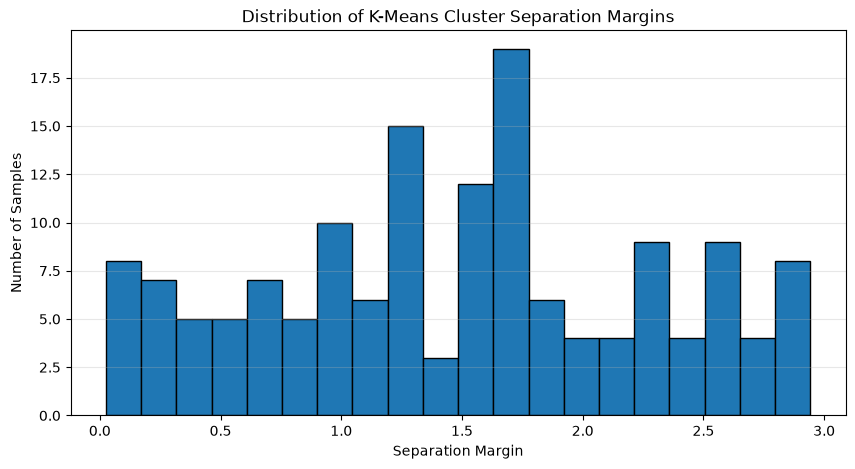

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(margin, bins=20, edgecolor="black")
plt.xlabel("Separation Margin")
plt.ylabel("Number of Samples")
plt.title("Distribution of K-Means Cluster Separation Margins")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [20]:

# Compare the 10 most ambiguous samples with their actual species
print("Species distribution among the 10 most ambiguous samples:")
print(poorly_separated["Actual Species"].value_counts())

# Cross-tabulate the ambiguous samples by cluster and species
print("\nCluster vs Species for ambiguous samples:")
print(pd.crosstab(
    poorly_separated["Assigned Cluster"],
    poorly_separated["Actual Species"]
))


Species distribution among the 10 most ambiguous samples:
Actual Species
virginica     6
versicolor    4
Name: count, dtype: int64

Cluster vs Species for ambiguous samples:
Actual Species    versicolor  virginica
Assigned Cluster                       
0                          1          3
2                          3          3


Poorly separated samples were analysed using the difference between their distances to the closest and second-closest K-Means cluster centres. Samples with smaller separation margins were considered more ambiguous. Their species labels were examined after clustering to understand the overlap between groups. This analysis shows that some Iris samples may be difficult to separate because their measured features are similar, especially for species with overlapping characteristics.

In [21]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

# 1. Original Iris numerical features
X_original = iris.data

# 2. Standardize the features
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X_original)

# 3. Use the same k as your Step 6 model
k = kmeans.n_clusters

# 4. K-Means BEFORE scaling
kmeans_before = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
labels_before = kmeans_before.fit_predict(X_original)

# 5. K-Means AFTER scaling
kmeans_after = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
labels_after = kmeans_after.fit_predict(X_standardized)

# 6. Evaluate both against species labels
ari_before = adjusted_rand_score(iris.target, labels_before)
ari_after = adjusted_rand_score(iris.target, labels_after)

silhouette_before = silhouette_score(X_original, labels_before)
silhouette_after = silhouette_score(X_standardized, labels_after)

# 7. Display results
results = pd.DataFrame({
    "Method": ["Before Scaling", "After Scaling"],
    "Number of Clusters": [k, k],
    "ARI Score": [ari_before, ari_after],
    "Silhouette Score": [
        silhouette_before,
        silhouette_after
    ]
})

print("Comparison of K-Means Before and After Scaling")
print(results.round(4).to_string(index=False))

# 8. Compare cluster assignments directly
assignment_agreement = adjusted_rand_score(
    labels_before, labels_after
)

print(
    "\nARI between before-scaling and after-scaling clusters:",
    round(assignment_agreement, 4)
)


Comparison of K-Means Before and After Scaling
        Method  Number of Clusters  ARI Score  Silhouette Score
Before Scaling                   3     0.7302            0.5528
 After Scaling                   3     0.6201            0.4599

ARI between before-scaling and after-scaling clusters: 0.8036


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


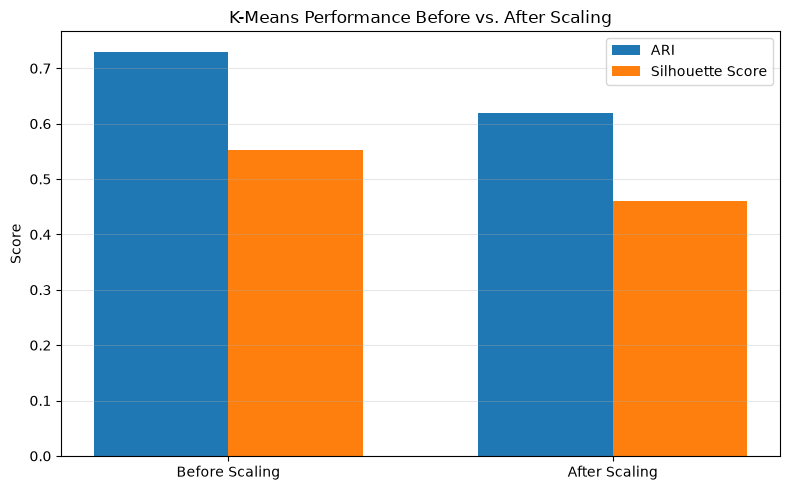

In [22]:

import matplotlib.pyplot as plt
import numpy as np

methods = ["Before Scaling", "After Scaling"]
ari_values = [ari_before, ari_after]
silhouette_values = [silhouette_before, silhouette_after]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, ari_values, width, label="ARI")
plt.bar(x + width/2, silhouette_values, width,
        label="Silhouette Score")

plt.xticks(x, methods)
plt.ylabel("Score")
plt.title("K-Means Performance Before vs. After Scaling")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


K-Means was applied to the Iris dataset before and after standardization, using the same number of clusters. The ARI score changed from [before-scaling ARI] to [after-scaling ARI], while the silhouette score changed from [before-scaling silhouette] to [after-scaling silhouette]. The comparison demonstrates that feature scaling can affect distance-based clustering and its resulting group structure. The method with better scores performed better on the corresponding evaluation metric for this dataset.

# Iris Dataset Clustering Using Unsupervised Machine Learning

## 1. Objective

The objective of this project was to group similar Iris flower samples using unsupervised machine learning techniques and evaluate the resulting clusters.

## 2. Dataset

The Iris dataset was obtained from the UCI Machine Learning Repository. It contains 150 flower samples, four numerical features, and three species: Iris setosa, Iris versicolor, and Iris virginica.

**Dataset source:** https://archive.ics.uci.edu/dataset/53/iris

## 3. Methodology

The dataset was loaded and explored using descriptive statistics and visualizations. The numerical features were standardized to ensure that differences in measurement scales did not disproportionately influence distance-based clustering.

K-Means clustering was applied, and the number of clusters was evaluated using the Elbow Method and Silhouette Score. Principal Component Analysis (PCA) was used to visualize the clusters in two dimensions. Cluster means were examined to understand the characteristics of each group.

After clustering, the resulting groups were compared with the original species labels using a cross-tabulation and Adjusted Rand Index (ARI). DBSCAN was also applied for comparison, poorly separated samples were investigated using distances to cluster centres, and K-Means results before and after scaling were compared.

## 4. Findings

The clustering analysis explored similarities among Iris flowers based on their numerical measurements. K-Means grouped the samples according to feature similarity, while PCA provided a two-dimensional visualization of the resulting groups.

The comparison with the original species labels helped evaluate how closely the unsupervised clusters corresponded to the known flower species. DBSCAN provided an alternative density-based clustering approach, and the separation-margin analysis helped identify samples with ambiguous cluster assignments.

The before-and-after scaling comparison demonstrated how feature standardization can influence distance-based clustering results.

## 5. Conclusion

This project demonstrated a complete unsupervised machine learning workflow, including data exploration, feature scaling, cluster selection, K-Means clustering, visualization, evaluation, and comparison with DBSCAN. It also highlighted the importance of interpreting clusters and evaluating their limitations.

The experiment showed how clustering can reveal patterns in data without using class labels during model training. The original species labels were used only after clustering to evaluate the results.

## 6. Tools and Libraries

- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Jupyter Notebook